<a href="https://colab.research.google.com/github/tenzin-selden/CNN-Handwritten--Digit-Recognition/blob/main/conv.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub
path = kagglehub.dataset_download("yjvision/handwritten-dzongkha-digits")

100%|██████████| 174M/174M [00:01<00:00, 119MB/s]

Extracting files...


In [ ]:
import os

print("data set path:",path)

data set path: /root/.cache/kagglehub/datasets/yjvision/handwritten-dzongkha-digits/versions/1


In [ ]:
for root, dirs, files in os.walk(path):
    print("\nFolder:", root)
    print("Subfolders:", dirs[:10])
    print("Files:", files[:10])


Folder: /root/.cache/kagglehub/datasets/yjvision/handwritten-dzongkha-digits/versions/1
Subfolders: ['input']
Files: []

Folder: /root/.cache/kagglehub/datasets/yjvision/handwritten-dzongkha-digits/versions/1/input
Subfolders: ['val', 'test', 'train']
Files: []

Folder: /root/.cache/kagglehub/datasets/yjvision/handwritten-dzongkha-digits/versions/1/input/val
Subfolders: ['1', '9', '6', '5', '4', '0', '8', '3', '7', '2']
Files: []

Folder: /root/.cache/kagglehub/datasets/yjvision/handwritten-dzongkha-digits/versions/1/input/val/1
Subfolders: []
Files: ['1639310949.3944693.jpg', '1632898574.0789278.jpg', '1630935704.17245.jpg', '1632901300.428428.jpg', '1630935704.149051.jpg', '1640842823.5824354.jpg', '1630992626.367136.jpg', '1642140686.242548.jpg', '1642140690.5617926.jpg', '1642140684.0943158.jpg']

Folder: /root/.cache/kagglehub/datasets/yjvision/handwritten-dzongkha-digits/versions/1/input/val/9
Subfolders: []
Files: ['1642141261.1468556.jpg', '1631287637.9956899.jpg', '1630851904

In [ ]:
import os

print(os.listdir(path))

['input']


In [ ]:
import os
print(os.listdir(os.path.join(path,"input")))

['val', 'test', 'train']


In [ ]:
train_path=os.path.join(path,"input","train")
print(os.listdir(train_path))

['1', '9', '6', '5', '4', '0', '8', '3', '7', '2']


In [ ]:
zero_path = os.path.join(train_path, "0")

print(os.listdir(zero_path)[:10])

['1632843901.007884.jpg', '1639228028.5537653.jpg', '1631767451.488513.jpg', '1639307447.9576604.jpg', '1639284282.2076144.jpg', '1632901969.1206698.jpg', '1632901308.872728.jpg', '1631841993.5646.jpg', '1639310003.9238813.jpg', '1630909281.378282.jpg']


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os

image_name=os.listdir(zero_path)[0]
print(image_name)



1632843901.007884.jpg


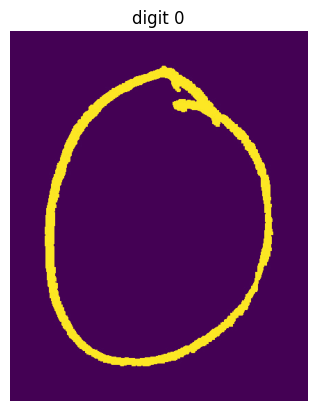

In [ ]:
image_path=os.path.join(zero_path,image_name)
img=Image.open(image_path)
plt.imshow(img)
plt.title("digit 0")
plt.axis("off")
plt.show()



In [ ]:
print("img size:",img.size)
print("img mode:",img.mode)

img size: (429, 533)
img mode: L


In [ ]:
for digit in range(10):
  digit_path=os.path.join(train_path,str(digit))
  img_files=os.listdir(digit_path)
  print("digit:",digit,"number of files:",len(img_files))


digit: 0 number of files: 1050
digit: 1 number of files: 1050
digit: 2 number of files: 1050
digit: 3 number of files: 1050
digit: 4 number of files: 1050
digit: 5 number of files: 1050
digit: 6 number of files: 1050
digit: 7 number of files: 1050
digit: 8 number of files: 1050
digit: 9 number of files: 1050


In [ ]:
import numpy as np
x_train=[]
y_train=[]
for digit in range(10):
  digit_path=os.path.join(train_path,str(digit)) #need to convert the digit to string before so that python can scan it
  for filename in os.listdir(digit_path):
      img_path=os.path.join(digit_path,filename)
      img = Image.open(img_path).convert("L")
      img= img.resize((64,64))

      x_train.append(np.array(img))
      y_train.append(np.array(digit))


x_train=np.array(x_train)
y_train=np.array(y_train)

print("image shape:",x_train.shape)
print("labelsshape:",y_train.shape)





image shape: (10500, 64, 64)
labelsshape: (10500,)


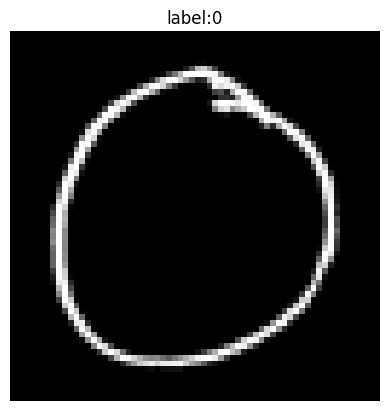

In [ ]:
import matplotlib.pyplot as plt
plt.imshow(x_train[0],cmap="gray")
plt.title(F"label:{y_train[0]}")
plt.axis("off")
plt.show()

In [ ]:
print("minimum pixel values:",x_train[0].min())
print("maximum pixel value:",x_train[0].max())
print("the first 10 pixel values of:",x_train[0].flatten()[:10])

minimum pixel values: 0
maximum pixel value: 255
the first 10 pixel values of: [0 0 0 0 0 0 0 0 0 0]


In [ ]:
x_train=x_train.astype("float32")/255.0 #normalize the pixel valus between 0-1 so that networks can train smoothly and easier to work on small no
print("the new minimum:",x_train.min())
print("the new maximum:",x_train.max())
print("the first 10 pixel values of:",x_train[0].flatten()[:10]) #[:10] is called slicing to just represent 10 no out of many
print("data type:",x_train.dtype)


the new minimum: 0.0
the new maximum: 1.0
the first 10 pixel values of: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
data type: float32


In [ ]:
val_path=os.path.join(path,"input","val")
test_path=os.path.join(path,"input","test")

for folder_name,folder_path in[
    ("validation",val_path),
     ("test",test_path)
]:
    print(folder_name,"folders:",os.listdir(folder_path))


validation folders: ['1', '9', '6', '5', '4', '0', '8', '3', '7', '2']
test folders: ['1', '9', '6', '5', '4', '0', '8', '3', '7', '2']


In [ ]:
def load_images(folder_path):
  images=[]
  labels=[]

  for digit in range(10):
    digit_path=os.path.join(folder_path,str(digit))
    for filename in os.listdir(digit_path):
      img_path=os.path.join(digit_path,filename)

      img=Image.open(img_path).convert("L")
      img=img.resize((64,64))

      images.append(np.array(img))
      labels.append(np.array(digit))
  images=np.array(images).astype("float32")/255.0
  labels=np.array(labels)

  return images,labels

x_val,y_val=load_images(val_path)
x_test,y_test=load_images(test_path)

print("validation images:",x_val.shape)
print("validation labels:",y_val.shape)

print("test images:",x_test.shape)
print("test labels:",y_test.shape)



validation images: (3000, 64, 64)
validation labels: (3000,)
test images: (1500, 64, 64)
test labels: (1500,)


In [ ]:
print(path)

/root/.cache/kagglehub/datasets/yjvision/handwritten-dzongkha-digits/versions/1


In [ ]:
import os
import numpy as np
from PIL import Image

train_path = os.path.join(path, "input", "train")

print(os.listdir(train_path))

['1', '9', '6', '5', '4', '0', '8', '3', '7', '2']


In [ ]:
X_train = []
y_train = []

for digit in range(10):
    digit_path = os.path.join(train_path, str(digit))

    for filename in os.listdir(digit_path):
        image_path = os.path.join(digit_path, filename)

        img = Image.open(image_path).convert("L")
        img = img.resize((64, 64))

        X_train.append(np.array(img))
        y_train.append(digit)

X_train = np.array(X_train).astype("float32") / 255.0
y_train = np.array(y_train)

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

Training images: (10500, 64, 64)
Training labels: (10500,)


In [ ]:
X_train = np.expand_dims(X_train, axis=-1)

print(X_train.shape)

(10500, 64, 64, 1)


In [ ]:
x_val=np.expand_dims(x_val,axis=-1)
x_test=np.expand_dims(x_test,axis=-1)
print("validation shape:",x_val.shape)
print("testing shape:",x_test.shape)

validation shape: (3000, 64, 64, 1)
testing shape: (1500, 64, 64, 1)


In [ ]:
import tensorflow as tf


In [ ]:
from tensorflow.keras import layers,models

In [ ]:
model= models.Sequential([               #conv has parameters as it learns weight and biases and max pooling doesnot have as it simply selects maximum(doesnot learn weight)
    layers.Input(shape=(64,64,1)),        #(3*3*32)+32 biases =320 parameters  #(12544*128)+128 biases=1605760

    layers.Conv2D(32,(3,3),                  #trainable params means parameters that can be adjusted and non trainable means the parameter that remains fixed during the training
activation="relu"),
    layers.MaxPooling2D((2,2)),                #the memory mentioned is the required storage amount to store models parameters

    layers.Conv2D(64,(3,3),
  activation="relu"),
  layers.MaxPooling2D((2,2)),

  layers.Flatten(),

  layers.Dense(128,activation="relu"),
  layers.Dropout(0.5),

  layers.Dense(10,
activation="softmax")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 62, 62, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,625,866 (6.20 MB)

 Trainable params: 1,625,866 (6.20 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam", #adjusts  model's internal weights to improve prediction

loss="sparse_categorical_crossentropy",#meausres how wrong the model's prediction are.works best when labels are integer classes
    metrics=["accuracy"]#tell the model to report the percentage of images it classified correctly
)

In [ ]:
import numpy as np
print("training labels:",np.unique(y_train))  #returns only the unique labels without repeating them
print("validation labels:",np.unique(y_val))
print("testing labels:",np.unique(y_test))

print("training images:",len(x_train))
print("training labels:",len(y_train))

training labels: [0 1 2 3 4 5 6 7 8 9]
validation labels: [0 1 2 3 4 5 6 7 8 9]
testing labels: [0 1 2 3 4 5 6 7 8 9]
training images: 10500
training labels: 10500


In [ ]:
history=model.fit( #history saves the training result so we can examine them later
    x_train,         #model.fit starts the training on x_train and Y_train and checks the performance on separate validation images after each epoch
    y_train,          #10500/32=329 batches
    validation_data=(x_val,y_val),
    epochs=10,
    batch_size=32
)

Epoch 1/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 62s 182ms/step - accuracy: 0.8657 - loss: 0.4322 - val_accuracy: 0.9700 - val_loss: 0.1105
Epoch 2/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 62s 187ms/step - accuracy: 0.9564 - loss: 0.1502 - val_accuracy: 0.9767 - val_loss: 0.0755
Epoch 3/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 61s 185ms/step - accuracy: 0.9694 - loss: 0.0980 - val_accuracy: 0.9830 - val_loss: 0.0802
Epoch 4/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 61s 184ms/step - accuracy: 0.9716 - loss: 0.0833 - val_accuracy: 0.9840 - val_loss: 0.0575
Epoch 5/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 61s 184ms/step - accuracy: 0.9788 - loss: 0.0626 - val_accuracy: 0.9803 - val_loss: 0.0667
Epoch 6/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 60s 183ms/step - accuracy: 0.9846 - loss: 0.0514 - val_accuracy: 0.9813 - val_loss: 0.0818
Epoch 7/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 80s 176ms/step - accuracy: 0.9855 - loss: 0.0447 - val_accuracy: 0.9853 - val_loss: 0.0642
Epoch 8/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 83s 180ms/step - accuracy: 0.9864 - loss: 0

In [ ]:
test_loss, test_accuracy = model.evaluate(
    x_test,      #1500/32=47 batches
    y_test
)
print("test loss:", test_loss)
print("test accuracy:", test_accuracy * 100, "%")

47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.9847 - loss: 0.0715
test loss: 0.07148873060941696
test accuracy: 98.4666645526886 %


In [ ]:
y_pred_prob=model.predict(x_test) #asking the trained model to predict on x_test images to see which digit it recognises correctly and which digit it confuses
y_pred=np.argmax(y_pred_prob,axis=1)       #1 stores the model confidence score for all 10 possible classes
print("first 10 actual labels:",y_test[:10]) #2 select the class with maximum score for each image
print("first 10 predicted labels:",y_pred[:10])

47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step
first 10 actual labels: [0 0 0 0 0 0 0 0 0 0]
first 10 predicted labels: [0 0 0 0 0 0 0 0 0 0]


In [ ]:
from sklearn.metrics import accuracy_score #compares actual labels in y_test with corresponding prediction in y_pred
accuracy=accuracy_score(y_test,y_pred)   #counts how many prediction are correct and divide that no by total no of test images
print("the test accuracy:",accuracy*100,"%")

the test accuracy: 98.46666666666667 %


since few images are misclassified incorrectly, we are using confusion matrix to investigate which digit the model confuses to recognize

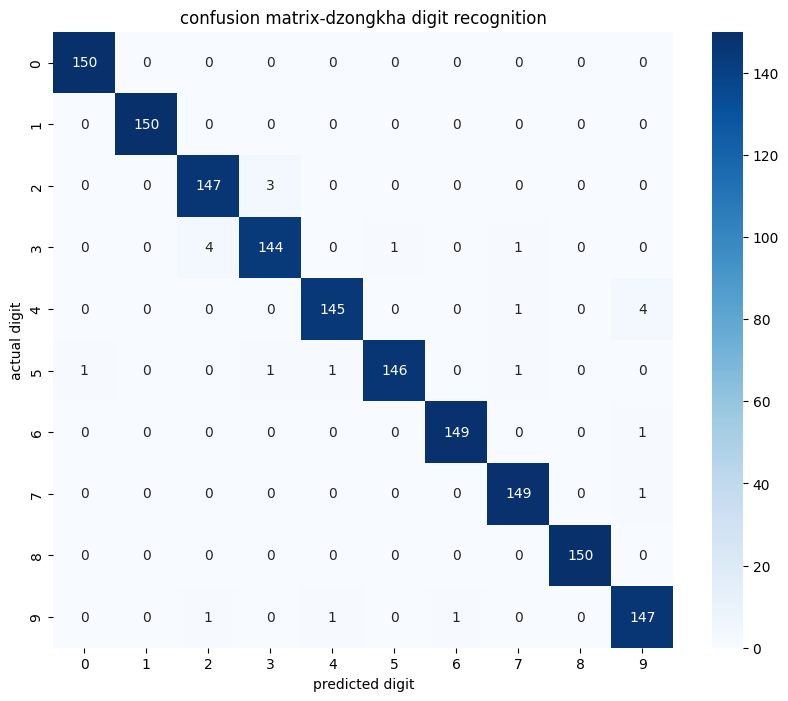

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns   #sns helps in creating attractive statistical charts.

cm=confusion_matrix(y_test,y_pred)

plt.figure(figsize=(10,8))  #sets the graph size with 10 width and 8 as height
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues") #display matrix using colors.annot=true allows us to write no inside cells.(fmt=d)-display no as whole integers

plt.xlabel("predicted digit")
plt.ylabel("actual digit")
plt.title("confusion matrix-dzongkha digit recognition")

plt.show()


the diagonal squares shows the correct prediction



-144 times the actual digit 3 was correctly predicted as 3


145 times the actual digit 4 was correctly prdicted as 4

 outside the main diagonal, such as the actual digit 4 was guessed as no 9 by model 4 times. this shows the model got confused and misclassified 4 as 9



 from the above matrix, it looks the models is getting confused between 3 and 2 and 9 and 4.  

In [ ]:
from sklearn.metrics import classification_report #precision(whether models prediction for a particular digit are correct)(correct prediction/total images)
print(classification_report(y_test,y_pred)) #recall(of all the images that truly contain  digit, how many did the model recognize) support- actul test images belonging to that digit.

              precision    recall  f1-score   support

           0       0.99      1.00      1.00       150
           1       1.00      1.00      1.00       150
           2       0.97      0.98      0.97       150
           3       0.97      0.96      0.97       150
           4       0.99      0.97      0.98       150
           5       0.99      0.97      0.98       150
           6       0.99      0.99      0.99       150
           7       0.98      0.99      0.99       150
           8       1.00      1.00      1.00       150
           9       0.96      0.98      0.97       150

    accuracy                           0.98      1500
   macro avg       0.98      0.98      0.98      1500
weighted avg       0.98      0.98      0.98      1500



the above results tells us that:
digit 9 as lowest precision.this means some images predicted as 9 actually belong to other digits



recall- digi 3 as lowest recall. this means model missed a larger proportion of actual 3s than other digits



f1score: 0,1 and 8 have displayed 1 which indicates excellent results on test sets

precison-the model sometimes predicts 9 when image actually conatains another digit


recall-model misses some actual images of digit 3 because it predicts another digit for them .

f1-how good is the overall balance